# Inferência — EfficientNetB0/PBC
Equipe: Felipe Brazão, Felipe Libório, Gabriel Góes e João Ricardo Almeida.

Uso de IA: versão inicial elaborada com apoio de ChatGPT/Codex; conferir a declaração completa no notebook principal. Este notebook **não treina**. Requer `models/selected.pt`, dependências e `src/pipeline.py`. Mantém a transformação e os índices das classes usados no treino. Nunca carregue checkpoints de origem desconhecida.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src/pipeline.py').exists() and (ROOT.parent / 'src/pipeline.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import pipeline as p
ROOT, DEVICE = p.setup(ROOT)
model = p.load_checkpoint(ROOT, 'selected', DEVICE)
print('Modelo carregado sem treinamento; classes:', p.CLASSES)
del model


{'torch': '2.15.0', 'torchvision': '0.29.2', 'numpy': '2.5.5', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'Pillow': '12.3.0', 'matplotlib': '3.11.2', 'python': '3.12.2', 'device': 'cpu', 'seed': 42}
Modelo carregado sem treinamento; classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


## Imagem externa
Escolha na internet uma imagem de uma das oito classes, preferencialmente de fonte educacional com identificação especializada. Salve uma cópia em `data/external/`. Informe o link da página da imagem e a classe esperada com base na fonte; não infira o rótulo pelo próprio modelo. Registre licença/atribuição quando aplicável. A imagem externa não substitui o teste e não exige um acerto.

Fonte: https://commons.wikimedia.org/wiki/File:Neutrophil.jpg 
Classe esperada: neutrophil 
Atribuição: Tommaso Leonardi — Neutrophil.jpg — Wikimedia Commons — domínio público.


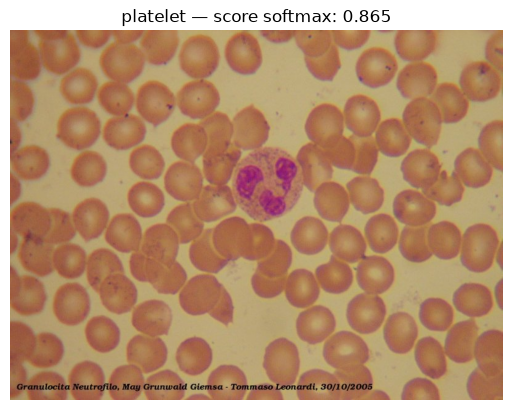

platelet        0.864545
eosinophil      0.125387
erythroblast    0.006523
neutrophil      0.002694
ig              0.000612
monocyte        0.000137
basophil        0.000073
lymphocyte      0.000030
dtype: float32

251

In [2]:
IMAGE_PATH = ROOT / 'data/external/fotografia-original.jpg'
SOURCE_URL = 'https://commons.wikimedia.org/wiki/File:Neutrophil.jpg'
EXPECTED_CLASS = 'neutrophil'
ATTRIBUTION = 'Tommaso Leonardi — Neutrophil.jpg — Wikimedia Commons — domínio público.'
if not SOURCE_URL.startswith('http') or EXPECTED_CLASS not in p.CLASSES:
    raise ValueError('Preencha a fonte e a classe esperada antes de executar.')
if not IMAGE_PATH.exists():
    raise FileNotFoundError('Salve a imagem externa e ajuste IMAGE_PATH.')
print('Fonte:', SOURCE_URL, '\nClasse esperada:', EXPECTED_CLASS, '\nAtribuição:', ATTRIBUTION)
probabilities = p.predict(ROOT, IMAGE_PATH, DEVICE)
display(probabilities)
result = dict(source=SOURCE_URL, expected=EXPECTED_CLASS, attribution=ATTRIBUTION,
              predicted=probabilities.index[0], score=float(probabilities.iloc[0]))
(ROOT / 'results/external_prediction.json').write_text(p.json.dumps(result, indent=2, ensure_ascii=False), encoding='utf-8')


## Comentário do resultado
A fonte identifica a célula como **neutrófilo**, mas o modelo selecionado previu **plaqueta**, com score softmax de **0,8645 (86,45%)**. Portanto, a execução funcionou, mas a classificação da imagem externa foi incorreta. Não houve novo treinamento nem alteração do modelo após observar esse resultado.

A foto de Tommaso Leonardi, disponibilizada em domínio público no Wikimedia Commons, tem 800×600 pixels, campo visual amplo, muitas hemácias e texto na borda inferior. A célula de interesse ocupa uma fração menor da imagem do que nas amostras PBC. A coloração também difere visualmente. Enquadramento, escala, fundo, texto e aquisição são hipóteses para a mudança de domínio; este caso não permite determinar qual fator causou o erro.

Foi preservado o pré-processamento da avaliação: RGB, resize direto 224×224 e normalização ImageNet. O score alto em uma previsão errada demonstra que softmax não equivale a uma probabilidade clínica calibrada. Este exemplo único demonstra a reutilização do checkpoint, mas não mede acurácia externa, não substitui o teste e não autoriza conclusões gerais sobre outras fontes. A lauda não exige acerto na imagem externa.
